# TP: ¿Cuánto cuesta un viaje en combustible? 100 vs 130 km/h

**Problema.** Antes de un viaje en auto queremos saber cuánto vamos a gastar en combustible, y cuánto
más cuesta ir rápido (~130 km/h) en vez de tranquilo (~100 km/h), con el precio del litro que habrá
**en la fecha del viaje** en cada provincia que atravesamos y el clima esperado ese día.

El trabajo sigue el pipeline de los tres ejercicios de referencia:

| Paso | Ejercicio de referencia | Acá |
|---|---|---|
| 1 | Web scraping / API → CSV | Descarga de precios por estación (Secretaría de Energía), inflación y dólar (ArgentinaDatos), provincias (Georef) |
| 2 | Detección de anomalías en series de tiempo | Saltos de precio (z-score móvil, STL, Isolation Forest) y estaciones con precios fuera de rango |
| 3 | Predicción con machine learning | Precio del litro a 1-3 meses por provincia, contra un modelo ingenuo, con validación temporal |

Además: una base propia de consumos de vehículos (con la fuente de cada fila) y un modelo físico simple
para pasar de 100 a 130 km/h, calibrado y validado con pruebas reales.

> Para correr este notebook: `docker compose run --rm datos` (descarga + procesamiento) y después
> `docker compose up app` → Jupyter en http://localhost:8888.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C, consumos, analisis
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Datos en:", C.DATA)

Datos en: /app/data


## 1. Datos (paso "API / descarga → CSV")

`src/descargar.py` baja todo con `requests`, en streaming y con reanudación (el histórico es grande),
respetando las fuentes (un pedido a la vez, pausas cortas). Todo queda como CSV en `data/raw`.

In [2]:
meta = json.loads((C.RAW / "_descargas.json").read_text()) if (C.RAW / "_descargas.json").exists() else {}
pd.DataFrame([{"fuente": k, "descargado": v.get("descargado"), "MB": round(v.get("bytes", 0) / 1e6, 1) or None}
              for k, v in meta.items()])

,fuente,descargado,MB
0,precios_vigentes,2026-11-17T16:03:39,9.3
1,macro,2026-11-05T19:48:42,NaN
2,georef,2026-11-05T19:48:43,NaN
3,precios_historicos,2026-11-06T18:08:34,779.1
4,etiqueta,2026-11-06T16:53:36,15.0


### 1.1 Calidad de los datos

Antes de usar nada revisamos cada archivo: columnas vacías, columnas con demasiadas categorías
(más de 255), precios imposibles (≤ 0 o absurdamente altos, típicamente una coma corrida al cargar),
provincias escritas de distintas formas ("CAPITAL FEDERAL" vs "Ciudad Autónoma de Buenos Aires") y
productos. El reporte completo queda en `reportes/calidad_*.md`.

In [3]:
from IPython.display import Markdown
Markdown((C.REPORTES / "calidad_precios_historicos.md").read_text())

# Calidad de datos: precios_historicos

Filas analizadas: 200,000

| columna | tipo | % vacíos | valores distintos | aviso |
|---|---|---|---|---|
| id_estacion | object | 0.0 | 380 | >255 categorías (no usar como categórica directa) |
| empresa | object | 0.0 | 285 | >255 categorías (no usar como categórica directa) |
| direccion | object | 0.0 | 380 | >255 categorías (no usar como categórica directa) |
| localidad | object | 0.0 | 240 |  |
| provincia | object | 0.0 | 22 |  |
| producto | object | 0.0 | 5 |  |
| horario | object | 0.0 | 2 |  |
| precio | float64 | 0.0 | 11,863 |  |
| fecha | datetime64[ns] | 0.0 | 32,352 |  |
| bandera | object | 0.0 | 13 |  |
| lat | float64 | 0.0 | 371 |  |
| lon | float64 | 0.0 | 371 |  |
| provincia_n | object | 0.0 | 22 |  |
| producto_n | object | 0.0 | 5 |  |
| fecha_original | object | 0.0 | 32,353 | >255 categorías (no usar como categórica directa) |

## Productos encontrados (nombre original -> clave)

- `Nafta (súper) entre 92 y 95 Ron` -> `nafta_comun` (811,817 filas)
- `Gas Oil Grado 2` -> `diesel_comun` (807,764 filas)
- `Gas Oil Grado 3` -> `diesel_premium` (801,416 filas)
- `Nafta (premium) de más de 95 Ron` -> `nafta_premium` (787,774 filas)
- `GNC` -> `gnc` (174,334 filas)

## Precios inválidos (<=0, vacíos o > 50.000): 235 de 3,383,105

## Fechas inválidas (vacías, antes de 2016 o futuras): 325. Ejemplos: 20/07/2007 10:30, 20/07/2007 10:30, 01/01/1572 00:00, 01/01/1572 00:00, 01/01/0008 08:00, 01/01/0008 08:00, 02/01/0002 19:45, 02/01/0002 19:45


Rango de meses: 2016-01 a 2026-11
Columnas originales: idempresa, empresa, direccion, localidad, provincia, idproducto, producto, idtipohorario, tipohorario, precio, fecha_vigencia, idempresabandera, empresabandera, latitud, longitud, geojson, anio, mes

## Cobertura: estaciones que informan nafta súper por mes (últimos 24 meses)

mes
2024-12-01    3637
2025-01-01    3643
2025-02-01    3594
2025-03-01    3576
2025-04-01    3557
2025-05-01    3513
2025-06-01    3407
2025-07-01    1625
2025-08-01    1480
2025-09-01    1238
2025-10-01    1103
2025-11-01    1098
2025-12-01     966
2026-01-01     690
2026-02-01     784
2026-03-01     892
2026-04-01     418
2026-05-01     731
2026-06-01     222
2026-07-01     334
2026-08-01     310
2026-09-01     697
2026-10-01     495
2026-11-01      16

OJO: la Res. 717/2025 (BO 2/6/2025) derogó la obligación de informar (Res. 314/2016); desde jul-2025 informan muchas menos estaciones.
Provincia-mes con menos de 3 estaciones (marcados no confiables): 551 de 13388


In [4]:
Markdown((C.REPORTES / "calidad_precios_vigentes.md").read_text())

# Calidad de datos: precios_vigentes

Filas analizadas: 36,613

| columna | tipo | % vacíos | valores distintos | aviso |
|---|---|---|---|---|
| indice_tiempo | object | 0.0 | 117 |  |
| id_estacion | object | 0.0 | 4,605 | >255 categorías (no usar como categórica directa) |
| empresa | object | 0.0 | 3,477 | >255 categorías (no usar como categórica directa) |
| direccion | object | 0.0 | 4,588 | >255 categorías (no usar como categórica directa) |
| localidad | object | 0.0 | 1,064 | >255 categorías (no usar como categórica directa) |
| provincia | object | 0.0 | 24 |  |
| producto | object | 0.0 | 5 |  |
| horario | object | 0.0 | 2 |  |
| precio | float64 | 0.0 | 2,923 |  |
| fecha | datetime64[ns] | 0.0 | 6,928 |  |
| bandera | object | 0.0 | 11 |  |
| lat | float64 | 0.0 | 4,468 |  |
| lon | float64 | 0.0 | 4,468 |  |
| provincia_n | object | 0.0 | 24 |  |
| producto_n | object | 0.0 | 5 |  |
| fecha_original | object | 0.0 | 6,928 | >255 categorías (no usar como categórica directa) |

Precios inválidos: 0 de 36,613
Fechas de vigencia: 2016-06-01 11:58:00 a 2026-11-14 06:00:00
Columnas originales: indice_tiempo, idempresa, cuit, empresa, direccion, localidad, provincia, region, idproducto, producto, idtipohorario, tipohorario, precio, fecha_vigencia, idempresabandera, empresabandera, latitud, longitud, geojson

## Productos

- `Gas Oil Grado 2` -> `diesel_comun` (8,337)
- `Nafta (súper) entre 92 y 95 Ron` -> `nafta_comun` (8,315)
- `Gas Oil Grado 3` -> `diesel_premium` (8,163)
- `Nafta (premium) de más de 95 Ron` -> `nafta_premium` (8,090)
- `GNC` -> `gnc` (3,708)

Estaciones sin coordenadas válidas: 18

## Estado de los precios 'vigentes'

estado          desactualizado (> 120 días)  fuera de rango    ok
producto_n                                                       
diesel_comun                           6772              10  1555
diesel_premium                         6586              21  1556
gnc                                    2911               2   795
nafta_comun                            6718              22  1575
nafta_premium                          6551              14  1525


### 1.2 Un quiebre en los datos: la derogación de la Res. 314/2016

La Res. 314/2016 obligaba a las estaciones a informar cada cambio de precio. La **Res. 717/2025 del
Ministerio de Economía (Boletín Oficial del 2/6/2025) la derogó**. Desde julio de 2025 informan muchas menos
estaciones. Consecuencias que tomamos en cuenta:
- el último precio de una estación se "arrastra" como mucho 3 meses (si lo arrastráramos más, estaciones que
  dejaron de informar hace un año bajarían la mediana artificialmente, porque los precios suben);
- una provincia-mes con menos de 3 estaciones se considera **no confiable** y no entra al modelo;
- el archivo de "precios vigentes" trae muchos precios viejos: sólo usamos los de los últimos 120 días.

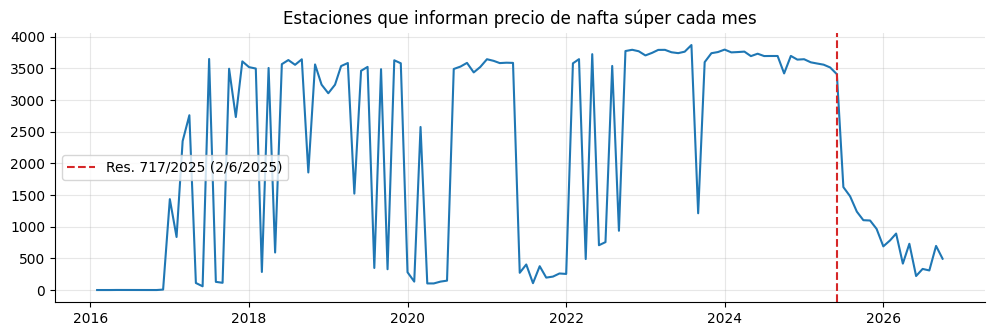

Promedio mensual ene-may 2025: 3576 | promedio desde jul-2025: 817


In [5]:
cob = pd.read_csv(C.REPORTES / "cobertura_mensual.csv", parse_dates=["mes"]).set_index("mes")
cob = cob[cob.index < pd.Timestamp.today().to_period("M").to_timestamp()]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(cob.index, cob.estaciones_que_informan, color="tab:blue")
ax.axvline(pd.Timestamp("2025-06-02"), color="tab:red", ls="--", label="Res. 717/2025 (2/6/2025)")
ax.set_title("Estaciones que informan precio de nafta súper cada mes"); ax.legend(); plt.show()
print("Promedio mensual ene-may 2025:", int(cob.loc["2025-01":"2025-05"].mean().iloc[0]),
      "| promedio desde jul-2025:", int(cob.loc["2025-07":].mean().iloc[0]))

**Cómo pasamos de reportes de estaciones a una serie mensual.** Las estaciones informan su precio
cuando cambia. Para cada estación, producto y horario tomamos el último precio informado de cada mes y lo
mantenemos vigente hasta 3 meses si no vuelve a informar (ver 1.2 por qué no más). Después calculamos, por provincia y mes, la
**mediana** de las estaciones (la mediana no se mueve por unas pocas estaciones con errores) habiendo
sacado antes las estaciones fuera de rango (ver 2.2).

Para comparar precios de distintos años los pasamos a **pesos constantes** (con el índice de inflación
mensual, base = último mes disponible) y a **dólares** (oficial, promedio mensual).

24 provincias, productos: ['diesel_comun', 'diesel_premium', 'nafta_comun', 'nafta_premium'], meses: 2017-01 a 2026-10


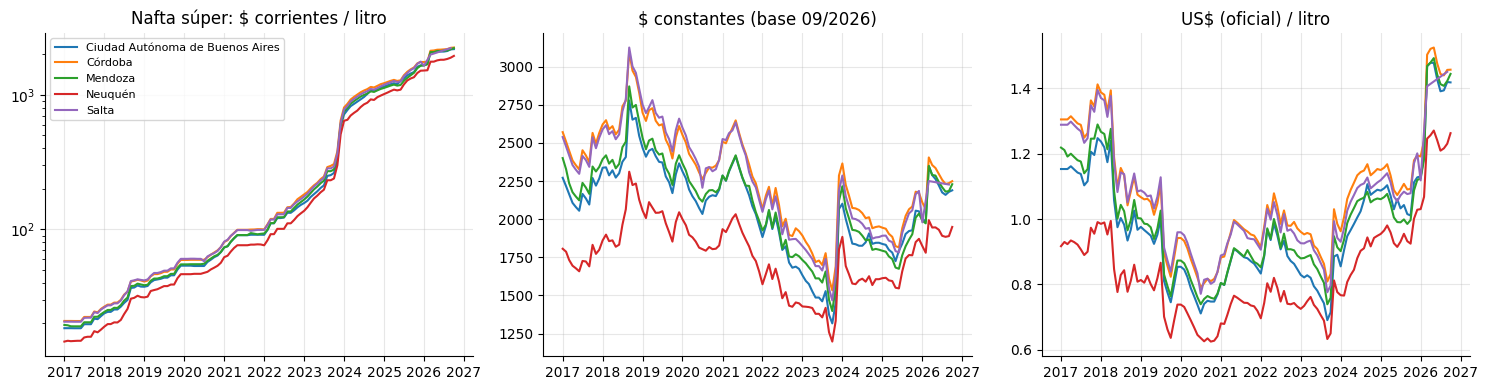

In [6]:
s = pd.read_parquet(C.PROC / "serie_real.parquet")
print(f"{s.provincia.nunique()} provincias, productos: {sorted(s.producto.unique())}, "
      f"meses: {s.mes.min():%Y-%m} a {s.mes.max():%Y-%m}")
provs = ["Ciudad Autónoma de Buenos Aires", "Córdoba", "Mendoza", "Neuquén", "Salta"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for p in provs:
    g = s[(s.provincia == p) & (s.producto == "nafta_comun")]
    ax[0].plot(g.mes, g.precio_mediana, label=p); ax[1].plot(g.mes, g.precio_real); ax[2].plot(g.mes, g.precio_usd)
ax[0].set_title("Nafta súper: $ corrientes / litro"); ax[0].set_yscale("log")
ax[1].set_title(f"$ constantes (base {s.base_ipc.iloc[0]:%m/%Y})"); ax[2].set_title("US$ (oficial) / litro")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

En pesos corrientes la curva sube siempre (inflación) y no dice mucho. En pesos constantes y en dólares
se ven los movimientos de verdad: períodos de congelamiento (el precio real cae) y saltos (devaluaciones,
liberación de precios).

## 2. Anomalías (paso "detección de anomalías en series de tiempo")

### 2.1 Saltos de precio en la serie mensual
Aplicamos tres métodos sobre el precio real de cada provincia y producto:

1. **z-score móvil**: compara la variación del mes contra la media y desvío de los 12 meses anteriores
   (sin mirar el futuro). Anomalía si |z| > 3.
2. **STL** (descomposición en tendencia + estacionalidad + residuo): anomalía si el residuo es muy grande
   (|z robusto| > 3,5).
3. **Isolation Forest**: un modelo de ML que mira varias variables a la vez (variación real y nominal,
   inflación, dólar, diferencia con el resto del país) y aísla los meses "raros" (3% más raro).

Un mes es "anómalo" con más confianza cuando lo marcan **2 o más métodos**.

In [7]:
a = pd.read_parquet(C.PROC / "anomalias_series.parquet")
print("Meses-provincia marcados por cada método:")
print(a[["anom_z", "anom_stl", "anom_iforest"]].sum().rename({"anom_z": "z-score", "anom_stl": "STL",
      "anom_iforest": "Isolation Forest"}))
print("\nCoincidencias (cantidad de métodos que marcan el mismo mes):")
print(a.n_metodos.value_counts().sort_index())

Meses-provincia marcados por cada método:
z-score              765
STL                 1509
Isolation Forest     322
dtype: int64

Coincidencias (cantidad de métodos que marcan el mismo mes):
n_metodos
0    9119
1    1526
2     325
3     140
Name: count, dtype: int64


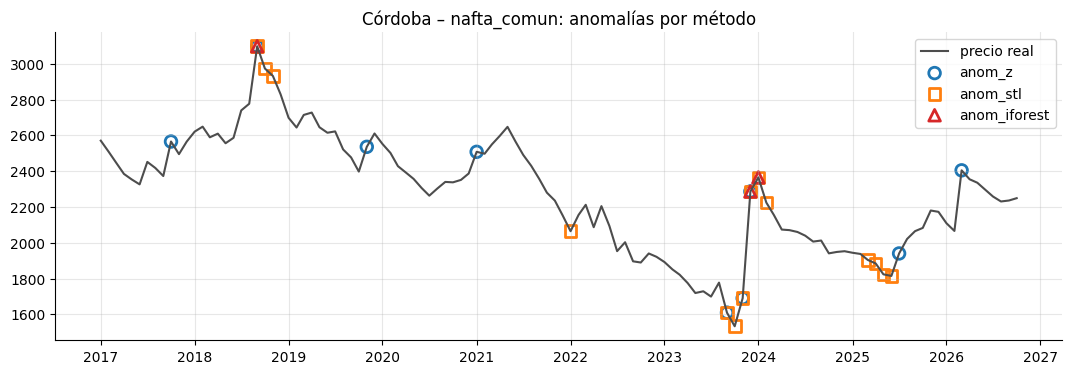

In [8]:
p, prod = "Córdoba", "nafta_comun"
g = a[(a.provincia == p) & (a.producto == prod)]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(g.mes, g.precio_real, color="0.3", lw=1.5, label="precio real")
for col, m, c in (("anom_z", "o", "tab:blue"), ("anom_stl", "s", "tab:orange"), ("anom_iforest", "^", "tab:red")):
    k = g[g[col]]
    ax.scatter(k.mes, k.precio_real, marker=m, s=70, facecolors="none", edgecolors=c, lw=2, label=col)
ax.set_title(f"{p} – {prod}: anomalías por método"); ax.legend(); plt.show()

**Tabla para interpretar** (meses donde ≥ 2 métodos coinciden, resumido a nivel país):

In [9]:
t = analisis.tabla_anomalias(a)
t.tail(25)

,mes,producto,provincias,var_nominal_med,var_real_med,var_usd,inflacion
20,2023-12-01,diesel_comun,24,52.6,29.9,57.4,25.5
21,2023-12-01,diesel_premium,24,46.2,23.5,57.4,25.5
22,2023-12-01,nafta_comun,24,52.4,29.7,57.4,25.5
23,2023-12-01,nafta_premium,24,49.6,26.9,57.4,25.5
24,2024-01-01,diesel_comun,23,23.1,4.4,24.4,20.6
25,2024-01-01,diesel_premium,20,22.3,3.6,24.4,20.6
26,2024-01-01,nafta_comun,24,23.1,4.4,24.4,20.6
27,2024-01-01,nafta_premium,24,23.1,4.4,24.4,20.6
28,2024-02-01,nafta_comun,6,1.7,-10.7,1.8,13.2
29,2024-02-01,nafta_premium,4,2.1,-10.3,1.8,13.2


In [10]:
cols = ["provincia", "producto", "mes", "var_nominal_%", "var_real_%", "inflacion_mm", "var_usd_%", "n_metodos", "interpretacion"]
a[a.n_metodos >= 2].sort_values("mes", ascending=False)[cols].head(20).round(1)

,provincia,producto,mes,var_nominal_%,var_real_%,inflacion_mm,var_usd_%,n_metodos,interpretacion
8410,San Juan,nafta_premium,2026-04-01,13.5,11.0,2.6,-0.7,2,"+13.5% nominal, +11.0% real; +12.6 pp distinto..."
6427,Misiones,nafta_comun,2026-03-01,19.9,16.5,3.4,-0.8,2,"+19.9% nominal, +16.5% real"
2234,Ciudad Autónoma de Buenos Aires,nafta_comun,2026-03-01,20.2,16.8,3.4,-0.8,2,"+20.2% nominal, +16.8% real"
2116,Ciudad Autónoma de Buenos Aires,diesel_premium,2026-03-01,20.2,16.9,3.4,-0.8,2,"+20.2% nominal, +16.9% real"
4788,La Pampa,diesel_comun,2026-03-01,21.2,17.9,3.4,-0.8,2,"+21.2% nominal, +17.9% real"
700,Catamarca,diesel_premium,2026-03-01,21.1,17.7,3.4,-0.8,2,"+21.1% nominal, +17.7% real"
818,Catamarca,nafta_comun,2026-03-01,20.3,16.9,3.4,-0.8,2,"+20.3% nominal, +16.9% real"
10866,Tucumán,diesel_premium,2026-03-01,22.0,18.7,3.4,-0.8,2,"+22.0% nominal, +18.7% real"
10984,Tucumán,nafta_comun,2026-03-01,20.4,17.0,3.4,-0.8,2,"+20.4% nominal, +17.0% real"
5955,Mendoza,nafta_comun,2026-03-01,20.8,17.5,3.4,-0.8,2,"+20.8% nominal, +17.5% real"


**Lectura.** Los saltos que marcan varios métodos y en muchas provincias a la vez son eventos de país
(devaluaciones, aumentos de las petroleras, cambios de impuestos). Los que aparecen en una sola provincia
con una diferencia grande contra el resto del país suelen ser problemas de datos locales (pocas estaciones
informando ese mes) o cambios impositivos provinciales.

### 2.2 Estaciones con precios fuera de rango
Para cada provincia, producto y mes comparamos cada estación contra la mediana provincial con un
**z robusto** (mediana y MAD). Se marca si |z| > 5, o si el precio es menos de la mitad o más del doble de la
mediana. Esto separa errores de carga (por ejemplo un precio 100 veces mayor: falta la coma) de precios
caros/baratos de verdad. Estas estaciones se excluyen del cálculo de la serie.

In [11]:
e = pd.read_parquet(C.PROC / "anomalias_estaciones.parquet")
print(e.motivo.value_counts())
cols = [c for c in ["fuente", "provincia_n", "producto_n", "mes", "bandera", "localidad", "precio", "ratio_mediana", "z_robusto", "motivo"] if c in e]
e.sort_values("ratio_mediana", ascending=False)[cols].head(15).round(2)

motivo
desvío estadístico fuerte (z robusto > 5)                     21502
menos de la mitad de la mediana provincial                      127
más del doble de la mediana provincial                           82
precio ~100x o más: probable error de carga (coma corrida)       53
Name: count, dtype: int64


,fuente,provincia_n,producto_n,mes,bandera,localidad,precio,ratio_mediana,z_robusto,motivo
12914,historico,Misiones,diesel_comun,2022-12-01,AXION,POSADAS,23670.0,113.31,1364.18,precio ~100x o más: probable error de carga (c...
16134,historico,Mendoza,gnc,2021-11-01,BLANCA,RIVADAVIA,5150.0,107.52,3584.76,precio ~100x o más: probable error de carga (c...
2973,historico,Mendoza,gnc,2022-05-01,BLANCA,SAN MARTIN,6850.0,107.21,4180.12,precio ~100x o más: probable error de carga (c...
14752,historico,Buenos Aires,gnc,2022-11-01,GULF,LA PLATA,8199.0,107.18,637.05,precio ~100x o más: probable error de carga (c...
9102,historico,Santa Fe,gnc,2021-07-01,BLANCA,VENADO TUERTO,4591.0,107.02,3067.69,precio ~100x o más: probable error de carga (c...
9104,historico,Santa Fe,gnc,2021-07-01,BLANCA,VENADO TUERTO,4591.0,107.02,3067.69,precio ~100x o más: probable error de carga (c...
2890,historico,Ciudad Autónoma de Buenos Aires,gnc,2020-11-01,SHELL C.A.P.S.A.,CAPITAL FEDERAL,2339.0,106.61,1488.44,precio ~100x o más: probable error de carga (c...
2891,historico,Ciudad Autónoma de Buenos Aires,gnc,2020-11-01,SHELL C.A.P.S.A.,CAPITAL FEDERAL,2339.0,106.61,1488.44,precio ~100x o más: probable error de carga (c...
16310,historico,Buenos Aires,gnc,2022-09-01,BLANCA,BARADERO,7399.0,105.87,810.41,precio ~100x o más: probable error de carga (c...
10880,historico,Buenos Aires,nafta_comun,2023-02-01,SHELL C.A.P.S.A.,SAN MIGUEL DEL MONTE,19509.0,104.94,1835.69,precio ~100x o más: probable error de carga (c...


### 2.3 ¿Qué se hizo con cada anomalía ANTES del modelo?

No todas las anomalías se tratan igual: los **errores de datos** se sacan; los **eventos reales**
(devaluaciones, aumentos) se dejan, porque son justamente lo que el modelo tiene que aprender.

In [12]:
L = json.loads((C.REPORTES / "resumen_limpieza.json").read_text())
a2 = int((a.n_metodos >= 2).sum())
pd.DataFrame([
    ["Precio <= 0, vacío o > $50.000", "regla fija", L["precios_invalidos_descartados"], "registro descartado"],
    ["Fecha imposible (antes de 2016 o futura)", "regla fija", L["fechas_invalidas_descartadas"], "registro descartado"],
    ["Estación con precio fuera de rango vs. su provincia", "z robusto (mediana/MAD) > 5 y >10% de diferencia, o < 0,5x / > 2x la mediana",
     L["estacion_mes_fuera_de_rango_excluidos"], "excluida de la mediana provincial"],
    [f"Provincia-mes con menos de {L['min_estaciones']} estaciones", "conteo", L["provincia_mes_no_confiables_excluidos"],
     "excluida de la serie del modelo"],
    ["Salto de precio en la serie (2+ métodos)", "z-score móvil, STL, Isolation Forest", a2,
     "SE MANTIENE (evento real); se documenta en la tabla 2.1"],
], columns=["anomalía", "cómo se detecta", "cantidad", "tratamiento"])

,anomalía,cómo se detecta,cantidad,tratamiento
0,"Precio <= 0, vacío o > $50.000",regla fija,235,registro descartado
1,Fecha imposible (antes de 2016 o futura),regla fija,325,registro descartado
2,Estación con precio fuera de rango vs. su prov...,z robusto (mediana/MAD) > 5 y >10% de diferenc...,40324,excluida de la mediana provincial
3,Provincia-mes con menos de 3 estaciones,conteo,551,excluida de la serie del modelo
4,Salto de precio en la serie (2+ métodos),"z-score móvil, STL, Isolation Forest",465,SE MANTIENE (evento real); se documenta en la ...


Ejemplos de fechas imposibles encontradas en el archivo oficial:

In [13]:
print(L["ejemplos_fechas_invalidas"])

['20/07/2007 10:30', '20/07/2007 10:30', '01/01/1572 00:00', '01/01/1572 00:00', '01/01/0008 08:00', '01/01/0008 08:00', '02/01/0002 19:45', '02/01/0002 19:45']


## 3. Predicción del precio del litro a 1, 2 y 3 meses (paso "machine learning")

**Qué predecimos:** el cambio porcentual (en log) del precio nominal del litro en cada provincia y producto
de acá a `h` meses (h = 1, 2, 3).

**Variables (sólo información disponible en el momento de predecir):** variaciones pasadas del precio
(1, 2, 3, 6, 12 meses), variación del dólar, inflación reciente, diferencia contra el promedio del país,
cuán "atrasado" está el precio real contra su promedio de 12 meses, y el mes del año.

**Modelos comparados:**
- **Ingenuo (último precio)**: el precio no cambia. Es la vara mínima que pidió la consigna.
- **Ingenuo + inflación**: el precio sube como la inflación de los últimos 3 meses.
- **Ridge** (regresión lineal regularizada) y **Gradient Boosting** (árboles).

**Validación temporal ("walk-forward")**: para cada mes de prueba entrenamos SOLO con datos anteriores
(cuyo resultado ya se conocía en ese momento) y predecimos hacia adelante. Nunca mezclamos al azar,
porque eso dejaría al modelo "ver el futuro".

In [14]:
r = pd.read_csv(C.REPORTES / "validacion_modelos.csv")
r

,h,modelo,MAPE_pct,mediana_err_pct,MAE_pesos,RMSE_pesos,R2_cambio,R2_nivel,acierto_direccion_real,n,mejora_vs_ingenuo_%
0,1,gradient boosting,3.193,1.728,56.700,100.840,-0.066,0.945,0.711,1065,25.408
1,1,ingenuo (último precio),4.280,2.643,73.282,115.763,-0.484,0.928,NaN,1065,0.000
2,1,ingenuo + inflación,3.521,2.215,62.693,100.283,-0.065,0.946,NaN,1065,17.733
3,1,ridge,3.598,2.201,64.698,108.021,-0.180,0.937,0.613,1065,15.942
4,2,gradient boosting,4.194,2.980,77.918,114.957,0.003,0.930,0.709,1052,27.885
5,2,ingenuo (último precio),5.816,4.345,101.356,145.555,-0.902,0.888,NaN,1052,0.000
6,2,ingenuo + inflación,5.106,4.563,89.161,116.374,-0.172,0.929,NaN,1052,12.213
7,2,ridge,5.792,4.883,100.306,133.903,-0.515,0.905,0.468,1052,0.408
8,3,gradient boosting,6.252,5.151,120.826,163.491,-0.292,0.873,0.636,1039,29.301
9,3,ingenuo (último precio),8.842,6.754,161.828,210.296,-1.714,0.790,NaN,1039,0.000


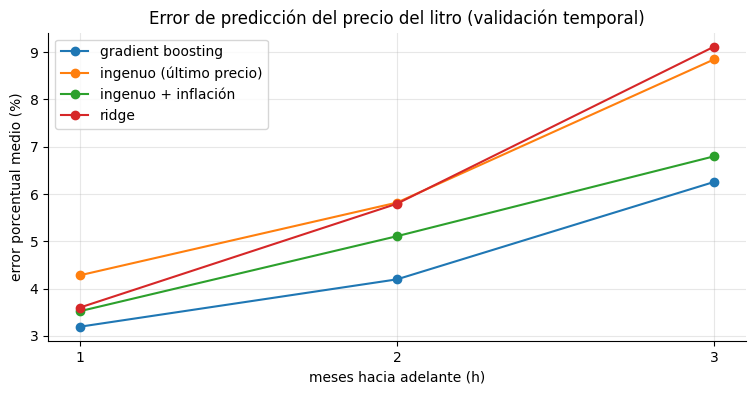

h=1: gana 'gradient boosting' con 3.19% de error (25% menos que el ingenuo; vs 'ingenuo + inflación': 3.52%)
h=2: gana 'gradient boosting' con 4.19% de error (28% menos que el ingenuo; vs 'ingenuo + inflación': 5.11%)
h=3: gana 'gradient boosting' con 6.25% de error (29% menos que el ingenuo; vs 'ingenuo + inflación': 6.79%)


In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
for m, g in r.groupby("modelo"):
    ax.plot(g.h, g.MAPE_pct, marker="o", label=m)
ax.set_xlabel("meses hacia adelante (h)"); ax.set_ylabel("error porcentual medio (%)"); ax.set_xticks([1, 2, 3])
ax.set_title("Error de predicción del precio del litro (validación temporal)"); ax.legend(); plt.show()
for h in (1, 2, 3):
    rh = r[r.h == h].set_index("modelo"); gana = rh.MAPE_pct.idxmin()
    if gana.startswith("ingenuo (último"):
        print(f"h={h}: NINGÚN modelo le gana al ingenuo -> usamos el último precio")
    else:
        print(f"h={h}: gana '{gana}' con {rh.loc[gana, 'MAPE_pct']:.2f}% de error "
              f"({rh.loc[gana, 'mejora_vs_ingenuo_%']:.0f}% menos que el ingenuo; "
              f"vs 'ingenuo + inflación': {rh.loc['ingenuo + inflación', 'MAPE_pct']:.2f}%)")

**Cómo leer las métricas**
- **MAPE** (error % medio) y **MAE** (error medio en $ por litro): el error típico.
- **RMSE** (en $): como el MAE pero castiga más los errores grandes (por ejemplo, no anticipar una devaluación).
- **R² del cambio**: qué parte de la variación del precio explica el modelo. 0 = no mejor que predecir
  el cambio promedio; negativo = peor.
- **R² del nivel**: R² sobre el precio en pesos. Da alto para *cualquier* modelo (incluso el ingenuo) porque
  los precios de 2017 y de 2026 son muy distintos: es una métrica **engañosa** acá, la mostramos para explicarlo.

In [16]:
cols = ["h", "modelo", "MAPE_pct", "MAE_pesos", "RMSE_pesos", "R2_cambio", "R2_nivel", "acierto_direccion_real"]
display(r[cols])
for h in (1, 2, 3):
    rh = r[r.h == h].set_index("modelo"); ml = rh.drop(["ingenuo (último precio)", "ingenuo + inflación"]).MAPE_pct.idxmin()
    ref = rh.loc["ingenuo + inflación"]
    comp = [f"{m}: {'mejor' if rh.loc[ml, m] < ref[m] else 'PEOR'} ({rh.loc[ml, m]:.2f} vs {ref[m]:.2f})"
            for m in ("MAPE_pct", "MAE_pesos", "RMSE_pesos")]
    print(f"h={h}: '{ml}' vs 'ingenuo + inflación' -> " + "; ".join(comp) + f"; R² cambio {rh.loc[ml, 'R2_cambio']:.2f}")

,h,modelo,MAPE_pct,MAE_pesos,RMSE_pesos,R2_cambio,R2_nivel,acierto_direccion_real
0,1,gradient boosting,3.193,56.700,100.840,-0.066,0.945,0.711
1,1,ingenuo (último precio),4.280,73.282,115.763,-0.484,0.928,NaN
2,1,ingenuo + inflación,3.521,62.693,100.283,-0.065,0.946,NaN
3,1,ridge,3.598,64.698,108.021,-0.180,0.937,0.613
4,2,gradient boosting,4.194,77.918,114.957,0.003,0.930,0.709
5,2,ingenuo (último precio),5.816,101.356,145.555,-0.902,0.888,NaN
6,2,ingenuo + inflación,5.106,89.161,116.374,-0.172,0.929,NaN
7,2,ridge,5.792,100.306,133.903,-0.515,0.905,0.468
8,3,gradient boosting,6.252,120.826,163.491,-0.292,0.873,0.636
9,3,ingenuo (último precio),8.842,161.828,210.296,-1.714,0.790,NaN


h=1: 'gradient boosting' vs 'ingenuo + inflación' -> MAPE_pct: mejor (3.19 vs 3.52); MAE_pesos: mejor (56.70 vs 62.69); RMSE_pesos: PEOR (100.84 vs 100.28); R² cambio -0.07
h=2: 'gradient boosting' vs 'ingenuo + inflación' -> MAPE_pct: mejor (4.19 vs 5.11); MAE_pesos: mejor (77.92 vs 89.16); RMSE_pesos: mejor (114.96 vs 116.37); R² cambio 0.00
h=3: 'gradient boosting' vs 'ingenuo + inflación' -> MAPE_pct: mejor (6.25 vs 6.79); MAE_pesos: mejor (120.83 vs 122.92); RMSE_pesos: PEOR (163.49 vs 149.96); R² cambio -0.29


**Importante para leer bien la tabla:** con inflación alta, el ingenuo "último precio" es fácil de vencer,
porque cualquier modelo que sume la inflación mejora. La comparación honesta es contra
**"ingenuo + inflación"**: si el ML no le gana a ese, el ML no aporta y lo decimos.

`acierto_direccion_real` mide (como el ejercicio de bitcoin, que predice si sube o baja) si el modelo acierta
cuando el precio sube **más o menos que la inflación**.

In [17]:
pron = pd.read_parquet(C.PROC / "pronosticos.parquet")
t = pron[pron.producto == "nafta_comun"].pivot_table(index="provincia", columns="h", values="precio_pred")
t.columns = [f"{h} mes(es)" for h in t.columns]
t.insert(0, "actual", pron[(pron.producto == "nafta_comun") & (pron.h == 1)].set_index("provincia").precio_actual)
print(f"Pronóstico nafta súper ($/litro), desde {pron.mes_origen.iloc[0]:%m/%Y}, modelo: {pron.modelo.unique()}")
t.round(0)

Pronóstico nafta súper ($/litro), desde 10/2026, modelo: ['gradient boosting']


,actual,1 mes(es),2 mes(es),3 mes(es)
provincia,,,,
Buenos Aires,2239.0,2270.0,2295.0,2368.0
Catamarca,2269.0,2299.0,2331.0,2396.0
Chaco,2199.0,2239.0,2262.0,2316.0
Chubut,2019.0,2051.0,2074.0,2147.0
Ciudad Autónoma de Buenos Aires,2189.0,2231.0,2258.0,2316.0
Corrientes,2146.0,2185.0,2208.0,2274.0
Córdoba,2249.0,2279.0,2305.0,2377.0
Entre Ríos,2245.0,2276.0,2312.0,2409.0
La Pampa,1882.0,1913.0,1933.0,1991.0


## 4. Consumo de los vehículos y el paso de 100 a 130 km/h

### 4.1 Base OFICIAL de consumos (Ministerio de Ambiente)
El dataset de la etiqueta vehicular de datos.gob.ar fue dado de baja (404). Los datos vigentes están en el
Centro de Información Ambiental (CIAM, dataset 566): un Excel de **Licencias de Configuración Ambiental** con el
consumo urbano / extraurbano / mixto certificado de cada configuración homologada. `src/descargar.py` lee la
página del CIAM, encuentra el enlace al Excel más nuevo y lo baja; `src/etiqueta.py` lo limpia y lo valida.

**Limitación de la fuente: no informa el año del modelo.** No lo inventamos: la app elige el vehículo por
marca → modelo → versión (denominación, caja, tracción y potencia del certificado), sin año.

**Limpieza de marcas y modelos** (`src/etiqueta.py`): homologaciones compartidas como "PEUGEOT / CITROËN" se
separan en una fila por marca (PARTNER / BERLINGO); "212" (marca todoterreno del grupo BAIC) pasa a BAIC
"212 T01"; "MERCEDES-AMG" a MERCEDES-BENZ "AMG ..."; "DFAC DONGFENG" a DONGFENG; "CITROEN" a "CITROËN";
"NUEVO DUSTER" a "DUSTER"; "CLASE GLC" a "GLC".

In [18]:
of = pd.read_csv(C.PROC / "consumos_oficiales.csv")
print(f"Configuraciones: {len(of):,} | marcas: {of.marca.nunique()} | usables: {int(of.usable.sum()):,} | "
      f"híbridos: {int(of.hibrido.sum())}")
print("\nProblemas encontrados (filas):")
print(of.problemas.fillna("").replace("", "ninguno").value_counts().head(10).to_string())
bo = consumos.cargar_base_oficial()
print(f"\nEn la app (nafta/diésel, usables, sin duplicados): {len(bo):,} configuraciones de {bo.marca.nunique()} marcas")

Configuraciones: 1,665 | marcas: 69 | usables: 1,477 | híbridos: 255

Problemas encontrados (filas):
problemas
ninguno                                                                                           1431
sin urbano; sin extraurbano; sin mixto;                                                             83
urbano < extraurbano;                                                                               61
urbano fuera de rango; extraurbano fuera de rango; mixto fuera de rango;                            12
urbano fuera de rango; mixto fuera de rango; urbano < extraurbano;                                  11
mixto fuera de [extra, urbano];                                                                     10
sin urbano; sin extraurbano; mixto fuera de rango;                                                  10
sin urbano; sin extraurbano;                                                                         9
urbano fuera de rango; extraurbano fuera de rango; mixto fuera de

### 4.2 Base propia y comparación con la oficial
Antes de encontrar la base oficial armamos una base con **27 versiones**
de los autos más vendidos con su consumo urbano / extraurbano / mixto y **la fuente de cada fila**
(etiquetas IRAM/AITA 10274 en PDF oficiales, fichas oficiales citadas por terceros, catálogos). Las filas
con dudas están marcadas como `aproximado` con la explicación. No se inventó ningún valor: cuando faltaba
el mixto se calculó con la ponderación del ciclo NEDC y se marcó. La app usa la base oficial; la base propia
queda para **validar** (abajo) y para vincular las pruebas reales a 100 km/h con las versiones oficiales.

Comparamos cada fila de la base propia con la configuración oficial más parecida (misma marca, familia y
combustible; la de consumo mixto más cercano). Ojo: elegir la más cercana hace que la diferencia sea la
**mínima posible**; si aun así es grande, la fila propia es dudosa.

In [19]:
b = consumos.cargar_base()
filas = []
for _, x in b.iterrows():
    o = bo[(bo.marca == x.marca.upper()) & (bo.modelo == x.modelo.upper()) & (bo.combustible == x.combustible)]
    if o.empty:
        filas.append([x.marca, x.modelo, x.version, x.ciclo, x.consumo_mixto_l100, None, None, "sin equivalente oficial"]); continue
    o = o.loc[(o.consumo_mixto_l100 - x.consumo_mixto_l100).abs().idxmin()]
    filas.append([x.marca, x.modelo, x.version, x.ciclo, x.consumo_mixto_l100, o.consumo_mixto_l100,
                  round((x.consumo_mixto_l100 / o.consumo_mixto_l100 - 1) * 100, 1), o.version[:60]])
comp = pd.DataFrame(filas, columns=["marca", "modelo", "version propia", "ciclo propio", "mixto propio",
                                    "mixto oficial", "dif %", "version oficial más parecida"])
comp

,marca,modelo,version propia,ciclo propio,mixto propio,mixto oficial,dif %,version oficial más parecida
0,Fiat,Cronos,Like / Drive 1.3 MT5,etiqueta IRAM/AITA 10274,6.0,6.000,0.0,CRONOS DRIVE 1.3. CRONOS 1.3 · manual · 4x2 · ...
1,Fiat,Cronos,Drive / Precision 1.3 CVT,etiqueta IRAM/AITA 10274,6.0,6.000,0.0,CRONOS DRIVE 1.3. CRONOS 1.3 · manual · 4x2 · ...
2,Fiat,Argo,Drive 1.3 MT5,etiqueta IRAM/AITA 10274,6.1,6.100,0.0,ARGO DRIVE 1.3 · manual · 4x2 · 73 kW
3,Fiat,Fiorino,Endurance 1.3 MT5,etiqueta IRAM/AITA 10274,6.8,6.765,0.5,FIORINO ENDURNCE 1.3L · manual · 4x2 · 71 kW
4,Toyota,Yaris,XS / XLS 1.5 MT (hatch y sedán),etiqueta IRAM/AITA 10274,6.2,6.150,0.8,YARIS · manual · 4x2 · 79 kW
5,Toyota,Yaris,1.5 CVT,etiqueta IRAM/AITA 10274,5.9,5.850,0.9,YARIS · automática CVT · 4x2 · 79 kW
6,Peugeot,208,Active / Allure 1.6 MT5,etiqueta IRAM/AITA 10274,7.3,7.230,1.0,208 · manual · 4x2 · 84 kW
7,Peugeot,208,Allure 1.6 AT6,etiqueta IRAM/AITA 10274,7.6,7.550,0.7,208 · automática · 4x2 · 84 kW
8,Peugeot,208,Allure Pack / GT T200 1.0 turbo,etiqueta IRAM/AITA 10274,6.8,6.800,0.0,208 GT T200 / 208 ALLURE T200 · automática CVT...
9,Volkswagen,Polo,Track 1.6 MSI MT5,etiqueta IRAM/AITA 10274,6.9,6.900,0.0,POLO · manual · 4x2 · 81 kW · motor VOLKSWAGEN...


In [20]:
print(b.tipo_fuente.value_counts(), "\nAproximados:", int(b.aproximado.sum()), "de", len(b))
b[["marca", "modelo", "version", "anio_desde", "anio_hasta", "combustible", "consumo_urbano_l100",
   "consumo_extraurbano_l100", "consumo_mixto_l100", "ciclo", "aproximado"]]

tipo_fuente
ficha oficial Toyota citada por tercero                   5
etiqueta oficial Ford citada por tercero                  5
catálogo Autocosmos Argentina                             4
ficha oficial Peugeot citada por tercero                  3
ficha oficial Fiat citada por tercero                     2
ficha oficial VW citada por tercero                       2
etiqueta oficial (PDF concesionario Fiat)                 1
informe de etiquetado oficial (PDF concesionario Fiat)    1
ficha técnica oficial Ford Argentina (PDF)                1
ficha Inmetro Brasil citada por tercero                   1
etiqueta oficial Renault Argentina (PDF)                  1
etiqueta oficial Nissan Argentina (PDF)                   1
Name: count, dtype: int64 
Aproximados: 9 de 27


,marca,modelo,version,anio_desde,anio_hasta,combustible,consumo_urbano_l100,consumo_extraurbano_l100,consumo_mixto_l100,ciclo,aproximado
0,Fiat,Cronos,Like / Drive 1.3 MT5,2025,2026,nafta,8.0,4.8,6.0,etiqueta IRAM/AITA 10274,False
1,Fiat,Cronos,Drive / Precision 1.3 CVT,2025,2026,nafta,7.9,5.0,6.0,etiqueta IRAM/AITA 10274,False
2,Fiat,Argo,Drive 1.3 MT5,2022,2023,nafta,8.1,5.0,6.1,etiqueta IRAM/AITA 10274,False
3,Fiat,Fiorino,Endurance 1.3 MT5,2023,2026,nafta,9.0,5.5,6.8,etiqueta IRAM/AITA 10274,True
4,Toyota,Yaris,XS / XLS 1.5 MT (hatch y sedán),2025,2026,nafta,7.9,5.1,6.2,etiqueta IRAM/AITA 10274,False
5,Toyota,Yaris,1.5 CVT,2025,2026,nafta,7.2,5.1,5.9,etiqueta IRAM/AITA 10274,True
6,Peugeot,208,Active / Allure 1.6 MT5,2025,2026,nafta,9.7,6.0,7.3,etiqueta IRAM/AITA 10274,False
7,Peugeot,208,Allure 1.6 AT6,2025,2026,nafta,10.0,6.2,7.6,etiqueta IRAM/AITA 10274,False
8,Peugeot,208,Allure Pack / GT T200 1.0 turbo,2025,2026,nafta,8.9,5.6,6.8,etiqueta IRAM/AITA 10274,False
9,Volkswagen,Polo,Track 1.6 MSI MT5,2025,2026,nafta,8.9,5.7,6.9,etiqueta IRAM/AITA 10274,False


### 4.3 Modelo físico

A velocidad constante el motor vence la **rodadura** (casi constante) y el **aire** (crece con el cuadrado de
la velocidad). Por eso:

$$ \text{consumo}(v) = c_{100} \cdot \left[(1-f) + f\left(\frac{v + v_{viento}}{100}\right)^2\right] $$

- $c_{100}$: consumo a 100 km/h. Si hay una medición real de esa versión la usamos; si no,
  $c_{100} = k \cdot$ extraurbano de la etiqueta (el ciclo extraurbano tiene velocidad media ~62 km/h y máxima 120,
  por eso hace falta corregirlo).
- $f$: qué parte del consumo a 100 km/h se va en vencer el aire.

Calibramos $k$ y $f$ con **pruebas reales a velocidad constante** (Auto Test, datos de fábrica):

k = 1.15 (rango intercuartil 1.12-1.20, 5 autos con etiqueta oficial y prueba a 100 km/h)
f = 0.47 (rango 0.40-0.55, 14 autos con prueba a 100 y 130 km/h)
=> ir a 130 km/h gasta ~32% más por km que ir a 100 km/h (rango 27%-38%)


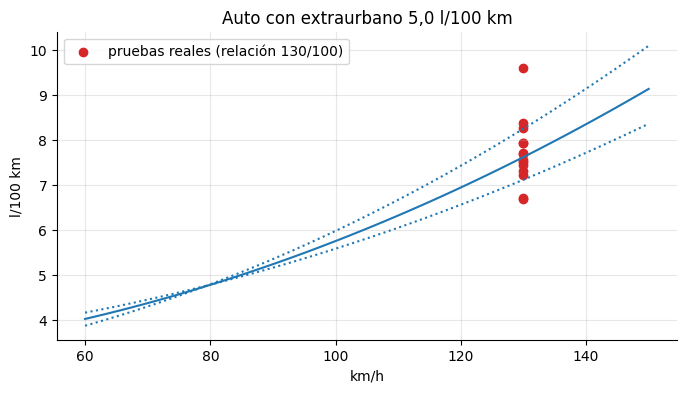

In [21]:
p = consumos.calibrar()
pr = consumos.cargar_pruebas()
print(f"k = {p.k_med:.2f} (rango intercuartil {p.k_p25:.2f}-{p.k_p75:.2f}, {p.n_k} autos con etiqueta oficial y prueba a 100 km/h)")
print(f"f = {p.f_med:.2f} (rango {p.f_p25:.2f}-{p.f_p75:.2f}, {p.n_f} autos con prueba a 100 y 130 km/h)")
print(f"=> ir a 130 km/h gasta ~{((1-p.f_med)+p.f_med*1.69-1)*100:.0f}% más por km que ir a 100 km/h "
      f"(rango {((1-p.f_p25)+p.f_p25*1.69-1)*100:.0f}%-{((1-p.f_p75)+p.f_p75*1.69-1)*100:.0f}%)")
v = np.linspace(60, 150, 50)
fig, ax = plt.subplots(figsize=(8, 4))
for esc, ls in (("bajo", ":"), ("med", "-"), ("alto", ":")):
    ax.plot(v, [consumos.consumo_velocidad(5.0, x, p, escenario=esc) for x in v], ls, color="tab:blue")
r130 = (pr.consumo_130_l100 / pr.consumo_100_l100).dropna() * consumos.consumo_velocidad(5.0, 100, p)
ax.scatter(np.full(len(r130), 130), r130, color="tab:red", label="pruebas reales (relación 130/100)")
ax.set_xlabel("km/h"); ax.set_ylabel("l/100 km"); ax.set_title("Auto con extraurbano 5,0 l/100 km"); ax.legend(); plt.show()

### 4.4 Validación "dejando uno afuera"
Para cada auto con prueba real, recalibramos **sin** ese auto y predecimos su consumo:

In [22]:
val = consumos.validar_modelo()
print(f"Error mediano a 130 km/h: {val['error_130_%'].abs().median():.1f}%  |  "
      f"a 100 km/h (desde la etiqueta): {val['error_100_%'].abs().median():.1f}%")
val

Error mediano a 130 km/h: 5.0%  |  a 100 km/h (desde la etiqueta): 8.8%


,vehiculo,real_100,pred_100,real_130,pred_130,error_100_%,error_130_%
0,Fiat Cronos 1.3 MT5,5.3,5.64,7.3,6.96,6.32,-4.64
1,Chevrolet Onix 1.0 turbo,5.0,9.10,6.7,6.57,81.94,-1.98
2,Toyota Yaris 1.5,5.7,5.99,7.6,7.49,5.04,-1.49
3,Fiat Argo Drive 1.3,6.4,5.67,NaN,8.47,-11.36,NaN
4,Volkswagen Polo versión no especificada,5.6,NaN,6.5,7.47,NaN,14.87
5,Peugeot 208 T200 1.0 turbo,6.7,6.35,8.8,8.93,-5.17,1.52
6,Peugeot 208 1.6 AT (generación anterior),6.6,NaN,7.7,8.80,NaN,14.29
7,Peugeot 208 1.6 MT5 Allure (generación anterior),5.9,NaN,7.4,7.87,NaN,6.31
8,Toyota Corolla Cross 2.0 nafta CVT,5.1,NaN,8.5,6.70,NaN,-21.19
9,Volkswagen Taos 1.4 250 TSI AT8 (2026),5.5,NaN,7.1,7.33,NaN,3.29


**Lectura.** Desde la etiqueta oficial la estimación a 100 km/h tiene errores chicos; las filas que vienen de
catálogos comerciales (Onix, Kwid) o del ciclo brasileño (Sandero RS) dan errores grandes: por eso las
marcamos como aproximadas y no las usamos para calibrar. El paso de 100 a 130 km/h (la parte física) se
predice con un error típico de pocos puntos porcentuales.

### 4.5 Ajustes por clima (supuestos)

In [23]:
from src import viaje
for k, t in viaje.AJUSTES_CLIMA.items():
    print(f"- {t}\n")

- Aire acondicionado: +0% si la máxima < 22 °C; +4% entre 22 y 27 °C; +7% entre 27 y 32 °C; +10% arriba de 32 °C. Supuesto propio dentro del rango del Dpto. de Energía de EE.UU. (fueleconomy.gov: el aire puede bajar el rendimiento más de 25% en calor extremo, sobre todo en viajes cortos; en ruta el efecto es menor).

- Lluvia: el asfalto mojado aumenta la resistencia a la rodadura. Tesis de Chalmers/Volvo (2025): en ruta muy mojada la resistencia total sube ~5% o más. Aplicamos +5% x probabilidad de lluvia (promedio de la probabilidad horaria del pronóstico entre las 8 y las 20 h, o la frecuencia histórica de días con lluvia si la fecha está a más de 15 días).

- Tramos urbanos o lentos (donde OSRM estima menos de 50 km/h: calles, avenidas, accesos y travesías por pueblos): se usa el consumo URBANO de la etiqueta oficial, sin importar la velocidad elegida para la ruta, y el tiempo se calcula con la velocidad de OSRM.

- Viento: se suma la componente de frente (o se resta la de cola) a 

## 5. Ejemplo de viaje (necesita internet: OSRM, Georef y Open-Meteo)

In [24]:
from datetime import date, timedelta
loc = viaje.localidades()
def lugar(nombre, prov):
    r = loc[(loc.nombre == nombre) & (loc.provincia == prov)].iloc[0]; return (r.lat, r.lon)
fila, _ = consumos.elegir(b, "Fiat", "Cronos", "Like / Drive 1.3 MT5", 2025, "nafta")
c100, fuente = consumos.c100_medido(fila.id)
try:
    R = viaje.calcular(lugar("Córdoba", "Córdoba"), lugar("Mendoza", "Mendoza"), date.today() + timedelta(days=10),
                       "nafta_comun", fila.consumo_extraurbano_l100, p, c100)
    print(f"Distancia: {R['km']:.0f} km | provincias: {R['km_provincia']}")
    for v_ in (100, 130):
        x = R["velocidades"][v_]
        print(f"{v_} km/h: {x['med']['litros']:.1f} l, $ {x['med']['costo']:,.0f} "
              f"(rango $ {x['bajo']['costo']:,.0f} - $ {x['alto']['costo']:,.0f}), {x['horas']:.1f} h de manejo")
    print(f"Ir a 130 cuesta $ {R['diferencia_pesos']:,.0f} más ({R['diferencia_pct']:.0f}%)")
    display(pd.DataFrame(R["precios"]).T)
    display(R["estaciones"])
except Exception as ex:
    print("No se pudo calcular (¿sin internet?):", ex)

Distancia: 689 km | provincias: {'Córdoba': 306.0, 'San Luis': 205.0, 'Mendoza': 177.60472044675657}
100 km/h: 34.6 l, $ 77,595 (rango $ 75,438 - $ 79,342), 7.3 h de manejo
130 km/h: 45.8 l, $ 102,723 (rango $ 98,400 - $ 107,016), 5.8 h de manejo
Ir a 130 cuesta $ 25,128 más (32%)


,precio,bajo,alto,metodo
Córdoba,2249.0,2219.0,2269.0,precio vigente (mediana de 99 estaciones con p...
San Luis,2259.0,2213.516779,2293.365101,precio vigente (sólo 1 estación(es) con precio...
Mendoza,2225.0,2204.0,2239.0,precio vigente (mediana de 12 estaciones con p...


,bandera,empresa,direccion,localidad,provincia_n,precio,fecha,km_del_viaje,dist_ruta_km,lat,lon
18580,GULF,JUAN BAUTISTA BERTINATTI,AV. 24 DE SETIEMBRE Nº 1896,CORDOBA,Córdoba,2106.0,2026-10-02 00:00:00,0.0,1.948775,-31.411913,-64.158891
346,PUMA,AD LITEM SAS,Sarmiento 499,CORDOBA,Córdoba,2155.0,2026-08-10 22:12:00,0.0,0.520447,-31.411580,-64.175420
15834,PUMA,GMJ SAS,RUTA N°8 KM 615,HOLMBERG,Córdoba,2217.0,2026-10-10 20:16:00,227.0,0.470066,-33.203828,-64.431504
34295,SHELL C.A.P.S.A.,SUN GROUP INVESTMENTS S.A.,GARIBALDI 588,MENDOZA,Mendoza,2221.0,2026-10-08 21:25:00,687.0,0.206418,-32.891192,-68.830971
31211,AXION,RUMBO SUR SRL,PASO DEL LOS PATOS ESQ MOLDES,GUAYMALLEN,Mendoza,2229.0,2026-10-29 00:24:00,686.0,1.995441,-32.914580,-68.824168
8319,PUMA,COPES SAS,COLON 1501,CORDOBA,Córdoba,2229.0,2026-11-02 22:08:00,0.0,2.465832,-31.407830,-64.203660
12020,AXION,ENCUENTRO G.N.C. S.R.L.,MANUEL BAIGORRIA 1388,CORDOBA,Córdoba,2239.0,2026-09-22 21:30:00,5.0,1.707915,-31.445373,-64.211992
14846,SHELL C.A.P.S.A.,GANP S.A.,GODOY CRUZ 6477,CAPILLA DEL ROSARIO,Mendoza,2239.0,2026-10-27 18:56:00,680.0,1.815257,-32.901885,-68.760231


## 6. Conclusiones

Los números de esta sección se calculan con los resultados de arriba (no están escritos a mano).

In [25]:
L = json.loads((C.REPORTES / "resumen_limpieza.json").read_text())
r = pd.read_csv(C.REPORTES / "validacion_modelos.csv").set_index(["h", "modelo"])
ml = "gradient boosting"
p = consumos.calibrar()
val = consumos.validar_modelo()
print(f"1. DATOS: {L['filas_leidas']:,} registros de precios por estación; {L['precios_invalidos_descartados']} precios "
      f"inválidos y {L['fechas_invalidas_descartadas']} fechas imposibles descartados; "
      f"{L['estacion_mes_fuera_de_rango_excluidos']:,} estación-mes fuera de rango excluidos; "
      f"serie final: {L['provincia_mes_total'] - L['provincia_mes_no_confiables_excluidos']:,} provincia-producto-mes confiables.")
print(f"2. ANOMALÍAS: {int((a.n_metodos >= 2).sum())} provincia-mes con saltos detectados por 2+ métodos; "
      f"los más fuertes coinciden con devaluaciones y congelamientos (tabla 2.1).")
for h in (1, 2, 3):
    g, i, ii = r.loc[(h, ml)], r.loc[(h, "ingenuo + inflación")], r.loc[(h, "ingenuo (último precio)")]
    print(f"3. PREDICCIÓN h={h}: {ml} MAPE {g.MAPE_pct:.1f}% vs ingenuo+inflación {i.MAPE_pct:.1f}% vs último precio "
          f"{ii.MAPE_pct:.1f}% | RMSE ${g.RMSE_pesos:.0f} vs ${i.RMSE_pesos:.0f} | R² del cambio {g.R2_cambio:.2f}")
print(f"4. VELOCIDAD: a 130 km/h se gasta ~{((1-p.f_med)+p.f_med*1.69-1)*100:.0f}% más por km que a 100 km/h "
      f"(rango {((1-p.f_p25)+p.f_p25*1.69-1)*100:.0f}-{((1-p.f_p75)+p.f_p75*1.69-1)*100:.0f}%); "
      f"error mediano de validación a 130 km/h: {val['error_130_%'].abs().median():.1f}%.")

1. DATOS: 3,383,105 registros de precios por estación; 235 precios inválidos y 325 fechas imposibles descartados; 40,324 estación-mes fuera de rango excluidos; serie final: 12,837 provincia-producto-mes confiables.
2. ANOMALÍAS: 465 provincia-mes con saltos detectados por 2+ métodos; los más fuertes coinciden con devaluaciones y congelamientos (tabla 2.1).
3. PREDICCIÓN h=1: gradient boosting MAPE 3.2% vs ingenuo+inflación 3.5% vs último precio 4.3% | RMSE $101 vs $100 | R² del cambio -0.07
3. PREDICCIÓN h=2: gradient boosting MAPE 4.2% vs ingenuo+inflación 5.1% vs último precio 5.8% | RMSE $115 vs $116 | R² del cambio 0.00
3. PREDICCIÓN h=3: gradient boosting MAPE 6.3% vs ingenuo+inflación 6.8% vs último precio 8.8% | RMSE $163 vs $150 | R² del cambio -0.29
4. VELOCIDAD: a 130 km/h se gasta ~32% más por km que a 100 km/h (rango 27-38%); error mediano de validación a 130 km/h: 5.0%.


**Interpretación**

1. **Los datos reales tenían problemas que una demo no muestra**: fechas imposibles, precios absurdos, un
   archivo de "vigentes" lleno de precios viejos y un quiebre por la derogación de la obligación de informar.
   La mayor parte del trabajo fue detectarlos y decidir qué hacer con cada uno (tabla 2.3).
2. **Anomalías**: los tres métodos coinciden en los eventos grandes; usarlos juntos sirve para separar eventos
   de país (muchas provincias a la vez) de problemas locales de datos (una sola provincia).
3. **Predicción**: hay que leer la tabla de la sección 3 completa. Ganarle al "último precio" es fácil con
   inflación; la vara honesta es "ingenuo + inflación". El R² del cambio cerca de 0 dice que **ningún modelo
   anticipa los saltos bruscos** (devaluaciones, liberación de precios): el modelo sirve para el "día a día"
   del precio, no para predecir shocks. Por eso la app muestra siempre un **rango**.
4. **Velocidad**: ir a 130 km/h en lugar de 100 km/h cuesta alrededor de un tercio más de combustible, a cambio
   de ~23% menos de tiempo de manejo. Es el resultado más robusto del trabajo (física simple + pruebas reales).

**Limitaciones**: la fuente oficial de consumos no informa el año; las pruebas a velocidad constante son
pocas y de pocas fuentes; los ajustes por clima son supuestos simples; la ruta no considera pendientes ni
tránsito; desde jul-2025 hay muchas menos estaciones informando precios.